# Finetune CourtHeatmapNet — bản TensorFlow/Keras

Notebook finetune model detect vạch sân (`model_tennis_court_det.pt`) bằng **TensorFlow/Keras**.

**Pipeline:**
1. Dựng lại đúng kiến trúc `CourtHeatmapNet` bằng Keras (Conv 3×3 → ReLU → BatchNorm, thứ tự y hệt PyTorch)
2. **Chuyển weights** từ file `.pt` (PyTorch) sang Keras — transpose kernel `(O,I,3,3)` → `(3,3,I,O)`, map BatchNorm đầy đủ
3. Load dataset `data.json`, sinh Gaussian heatmap target 15 channel
4. Finetune 2 phase: freeze encoder → train decoder, rồi unfreeze toàn mạng
5. Đánh giá (mean pixel error, PCK) và **visualize so sánh trước/sau**
6. Lưu weights Keras **+ chuyển ngược về `.pt`** để thay vào pipeline PyTorch gốc (`models/`)

**Chuẩn bị:** file `data.json` + ảnh, file `model_tennis_court_det.pt` → sửa đường dẫn ở cell **Cấu hình**.


In [ ]:
import tensorflow as tf
print("tensorflow:", tf.__version__)
print("gpu:", tf.config.list_physical_devices("GPU"))

# torch CHỈ dùng để đọc file .pt (pickle) khi chuyển weights, không dùng để train
import importlib, subprocess, sys
for pkg, imp in [("torch --index-url https://download.pytorch.org/whl/cpu", "torch"),
                 ("opencv-python", "cv2"), ("matplotlib", "matplotlib")]:
    try:
        importlib.import_module(imp)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install"] + pkg.split())
import torch
print("torch (chi de doc .pt):", torch.__version__)


## 1. Cấu hình

In [ ]:
# Mount Google Drive (chỉ chạy trên Colab; tự bỏ qua nếu đã mount từ trước)
import os
try:
    from google.colab import drive
    if os.path.ismount('/content/drive'):
        print("Drive đã được mount, bỏ qua.")
    else:
        drive.mount('/content/drive')
except ImportError:
    print("Không chạy trên Colab -> bỏ qua mount Drive.")
from pathlib import Path

# ============ SỬA ĐƯỜNG DẪN TẠI ĐÂY ============
DATA_JSON  = "/content/drive/MyDrive/tennis/court/data.json"
IMG_ROOT   = "/content/drive/MyDrive/tennis/court"
WEIGHTS_PT = "/content/drive/MyDrive/tennis/court/model_tennis_court_det.pt"
OUT_DIR    = "/content/drive/MyDrive/tennis/court/finetune_tf_out"
DATA_ZIP   = "/content/drive/MyDrive/tennis/court/court_data.zip"  # zip: data.json + ảnh + .pt (upload 1 lần); để "" nếu không dùng
# ==============================================

IMG_W, IMG_H = 640, 360
N_KPS = 14
SIGMA = 7.0
BATCH = 8
EPOCHS_FREEZE = 5
EPOCHS_FULL = 15
LR_HEAD = 1e-3
LR_FULL = 1e-4
VAL_RATIO = 0.1
AUG_FLIP = True
AUG_COLOR = True
SEED = 42

import random, numpy as np
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
print("config ok")


## 1b. Chuẩn bị dữ liệu: GPU Colab + data từ máy local

**Chuẩn bị 1 lần duy nhất trên máy local:**
1. Nén thư mục dữ liệu thành `court_data.zip` sao cho trong zip có:
   - `data.json`
   - các thư mục ảnh đúng cấu trúc mà `id` trong `data.json` trỏ tới (ví dụ `train/images/...`)
   - `model_tennis_court_det.pt`
2. Upload `court_data.zip` lên Google Drive (kéo-thả trên trình duyệt, hoặc Drive for Desktop đều được).

Cell dưới sẽ tự giải nén vào ổ SSD của Colab (`/content/court_data` — I/O nhanh khi train) và trỏ mọi đường dẫn sang đó. Kết quả train vẫn lưu trên Drive (`OUT_DIR`) nên không mất khi Colab reset máy.

*Không muốn nén zip?* Đặt `DATA_ZIP = ""` — notebook sẽ đọc trực tiếp từ đường dẫn Drive trong cell cấu hình (chậm hơn một chút do I/O qua Drive).

In [32]:
import zipfile

work = Path("/content/court_data")
if DATA_ZIP and Path(DATA_ZIP).exists():
    marker = work / ".unzipped_ok"
    if marker.exists():
        print("dữ liệu đã giải nén từ trước, bỏ qua (muốn giải nén lại: xóa /content/court_data rồi chạy lại cell này)")
    else:
        print("đang giải nén:", DATA_ZIP)
        work.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(DATA_ZIP) as z:
            z.extractall(work)
        marker.touch()
        print("giải nén xong ->", work)
    # trỏ mọi đường dẫn sang ổ local của Colab (I/O nhanh)
    DATA_JSON = str(work / "court_data/data.json")
    IMG_ROOT = r"/content/court_data/court_data"
    pts = list(work.rglob("model_tennis_court_det.pt"))
    if pts:
        WEIGHTS_PT = str(pts[0])
    print("DATA_JSON :", DATA_JSON)
    print("IMG_ROOT  :", IMG_ROOT)
    print("WEIGHTS_PT:", WEIGHTS_PT)
    assert Path(DATA_JSON).exists(), "không thấy data.json trong zip - kiểm tra lại cấu trúc file zip"
else:
    print("không dùng zip, giữ nguyên đường dẫn trong cell cấu hình")


dữ liệu đã giải nén từ trước, bỏ qua (muốn giải nén lại: xóa /content/court_data rồi chạy lại cell này)
DATA_JSON : /content/court_data/court_data/data.json
IMG_ROOT  : /content/court_data/court_data
WEIGHTS_PT: /content/court_data/court_data/model_tennis_court_det.pt


## 2. Kiến trúc Keras (tương đương 1-1 với PyTorch)

Thứ tự trong ConvBlock của PyTorch là **Conv → ReLU → BatchNorm** (khác convention thường gặp) — dựng lại y hệt, BatchNorm `epsilon=1e-5` cho khớp PyTorch, Upsample dùng nearest (mặc định cả 2 bên).

In [33]:
from tensorflow.keras import layers, models

def conv_block(x, filters, name):
    x = layers.Conv2D(filters, 3, padding="same", name=f"{name}_conv")(x)
    x = layers.ReLU(name=f"{name}_relu")(x)
    x = layers.BatchNormalization(epsilon=1e-5, name=f"{name}_bn")(x)  # epsilon khớp PyTorch
    return x

def build_court_heatmap_net():
    inp = layers.Input(shape=(IMG_H, IMG_W, 3), name="input")
    x = conv_block(inp, 64, "conv1");  x = conv_block(x, 64, "conv2")
    x = layers.MaxPooling2D(2, name="pool1")(x)
    x = conv_block(x, 128, "conv3");   x = conv_block(x, 128, "conv4")
    x = layers.MaxPooling2D(2, name="pool2")(x)
    x = conv_block(x, 256, "conv5");   x = conv_block(x, 256, "conv6"); x = conv_block(x, 256, "conv7")
    x = layers.MaxPooling2D(2, name="pool3")(x)
    x = conv_block(x, 512, "conv8");   x = conv_block(x, 512, "conv9"); x = conv_block(x, 512, "conv10")
    x = layers.UpSampling2D(2, name="ups1")(x)
    x = conv_block(x, 256, "conv11");  x = conv_block(x, 256, "conv12"); x = conv_block(x, 256, "conv13")
    x = layers.UpSampling2D(2, name="ups2")(x)
    x = conv_block(x, 128, "conv14");  x = conv_block(x, 128, "conv15")
    x = layers.UpSampling2D(2, name="ups3")(x)
    x = conv_block(x, 64, "conv16");   x = conv_block(x, 64, "conv17"); x = conv_block(x, N_KPS + 1, "conv18")  # 15 = 14 keypoint + background
    out = layers.Activation("sigmoid", name="sigmoid")(x)  # runtime PyTorch áp sigmoid ở predict()
    return models.Model(inp, out, name="CourtHeatmapNet")

def transfer_pt_to_keras(pt_path, keras_model):
    """Chuyển weights PyTorch .pt -> Keras. Cần torch (CPU) chỉ để đọc pickle."""
    import torch
    sd = torch.load(pt_path, map_location="cpu")
    if isinstance(sd, dict) and "state_dict" in sd:
        sd = sd["state_dict"]
    sd = {k.replace("module.", ""): v for k, v in sd.items()}
    for i in range(1, 19):
        name = f"conv{i}"
        W = sd[f"{name}.block.0.weight"].numpy()      # (O, I, 3, 3)
        b = sd[f"{name}.block.0.bias"].numpy()        # (O,)
        gamma = sd[f"{name}.block.2.weight"].numpy()
        beta  = sd[f"{name}.block.2.bias"].numpy()
        mean  = sd[f"{name}.block.2.running_mean"].numpy()
        var   = sd[f"{name}.block.2.running_var"].numpy()
        keras_model.get_layer(f"{name}_conv").set_weights([W.transpose(2, 3, 1, 0), b])  # -> (3,3,I,O)
        keras_model.get_layer(f"{name}_bn").set_weights([gamma, beta, mean, var])
    print("chuyen weights .pt -> Keras xong:", pt_path)

model_before = build_court_heatmap_net()
transfer_pt_to_keras(WEIGHTS_PT, model_before)
model_before.summary()

# sanity check: output shape
import numpy as np
y = model_before.predict(np.zeros((1, IMG_H, IMG_W, 3), dtype=np.float32), verbose=0)
print("output shape:", y.shape, "(expect (1, 360, 640, 15))")


chuyen weights .pt -> Keras xong: /content/court_data/court_data/model_tennis_court_det.pt


Model: "CourtHeatmapNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 360, 640, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_conv (Conv2D)             │ (None, 360, 640, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 360, 640, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 360, 640, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_conv (Conv2D)             │ (None, 360, 640, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_relu (ReLU)               │ (None, 360, 640, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_bn (BatchNormalization)   │ (None, 360, 640, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 180, 320, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_conv (Conv2D)             │ (None, 180, 320, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_relu (ReLU)               │ (None, 180, 320, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_bn (BatchNormalization)   │ (None, 180, 320, 128)  │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4_conv (Conv2D)             │ (None, 180, 320, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4_relu (ReLU)               │ (None, 180, 320, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4_bn (BatchNormalization)   │ (None, 180, 320, 128)  │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 90, 160, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5_conv (Conv2D)             │ (None, 90, 160, 256)   │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5_relu (ReLU)               │ (None, 90, 160, 256)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5_bn (BatchNormalization)   │ (None, 90, 160, 256)   │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6_conv (Conv2D)             │ (None, 90, 160, 256)   │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6_relu (ReLU)               │ (None, 90, 160, 256)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6_bn (BatchNormalization)   │ (None, 90, 160, 256)   │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv7_conv (Conv2D)             │ (None, 90, 160, 256)   │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv7_relu (ReLU)               │ (None, 90, 160, 256)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv7_bn (BatchNormalization)   │ (None, 90, 160, 256)   │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 45, 80, 256)    │             

 Total params: 10,572,747 (40.33 MB)

 Trainable params: 10,565,037 (40.30 MB)

 Non-trainable params: 7,710 (30.12 KB)

output shape: (1, 360, 640, 15) (expect (1, 360, 640, 15))


## 3. Dataset: ảnh + Gaussian heatmap targets

- Đọc `data.json`; keypoint `(0,0)` = thiếu → invisible, mask khỏi loss.
- Target `HxWx15`: mỗi keypoint visible là Gaussian 2D (sigma=7); background = `1 − max(14 heatmap)`.
- Augment: lật ngang có remap cặp trái/phải `(0,1),(2,3),(4,6),(5,7),(8,9),(10,11)` + jitter màu.

In [34]:
import json, cv2, math
import numpy as np
import tensorflow as tf
from pathlib import Path

records = json.load(open(DATA_JSON))
print("records:", len(records))

# lưới tọa độ dùng chung (numpy, vector hoá)
_ys, _xs = np.mgrid[0:IMG_H, 0:IMG_W].astype(np.float32)  # (H,W) mỗi cái

def make_targets_np(kps_px, vis):
    # kps_px: (14,2) pixel hệ 640x360; vis: (14,) bool -> (H,W,15)
    cx = kps_px[:, 0].reshape(N_KPS, 1, 1)
    cy = kps_px[:, 1].reshape(N_KPS, 1, 1)
    g = np.exp(-((_xs - cx) ** 2 + (_ys - cy) ** 2) / (2 * SIGMA ** 2))  # (14,H,W)
    g = g * vis.reshape(N_KPS, 1, 1)
    bg = np.clip(1.0 - g.max(axis=0), 0, 1)
    return np.concatenate([g.transpose(1, 2, 0), bg[..., None]], axis=-1)  # HxWx15

FLIP_SWAP = [(0, 1), (2, 3), (4, 6), (5, 7), (8, 9), (10, 11)]

def load_sample(rec, augment):
    img = cv2.imread(str(Path(IMG_ROOT) / rec["id"]))
    if img is None:
        raise FileNotFoundError(rec["id"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_W, IMG_H))
    kps = np.array(rec["kps"], dtype=np.float32).reshape(N_KPS, 2)
    vis = ~((kps[:, 0] == 0) & (kps[:, 1] == 0))
    kps_px = kps.copy()
    kps_px[:, 0] *= IMG_W
    kps_px[:, 1] *= IMG_H
    if augment and AUG_FLIP and np.random.rand() < 0.5:
        img = img[:, ::-1, :].copy()
        kps_px[:, 0] = IMG_W - kps_px[:, 0]
        for a, b in FLIP_SWAP:
            kps_px[[a, b]] = kps_px[[b, a]]
            vis[[a, b]] = vis[[b, a]]
    if augment and AUG_COLOR:
        img = np.clip(img.astype(np.float32) * np.random.uniform(0.85, 1.15)
                      + np.random.uniform(-15, 15), 0, 255).astype(np.uint8)
    img_f = (img.astype(np.float32) / 255.0)
    tgt = make_targets_np(kps_px, vis).astype(np.float32)
    return img_f, tgt, vis.astype(np.float32)

def make_ds(recs, augment, shuffle):
    def gen():
        for r in recs:
            yield load_sample(r, augment)
    ds = tf.data.Dataset.from_generator(
        gen,
        output_signature=(
            tf.TensorSpec((IMG_H, IMG_W, 3), tf.float32),
            tf.TensorSpec((IMG_H, IMG_W, N_KPS + 1), tf.float32),
            tf.TensorSpec((N_KPS,), tf.float32)))
    if shuffle:
        ds = ds.shuffle(512, seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

# kiểm tra ảnh tồn tại
missing = [r["id"] for r in records[:200] if not (Path(IMG_ROOT) / r["id"]).exists()]
print("thiếu ảnh trong 200 mẫu đầu:", len(missing), missing[:3])

rng = np.random.RandomState(SEED)
idx = rng.permutation(len(records))
n_val = max(1, int(len(records) * VAL_RATIO))
va_idx, tr_idx = idx[:n_val], idx[n_val:]
tr_recs = [records[i] for i in tr_idx]
va_recs = [records[i] for i in va_idx]
print(f"train: {len(tr_recs)} | val: {len(va_recs)}")

ds_tr = make_ds(tr_recs, augment=True, shuffle=True)
ds_va = make_ds(va_recs, augment=False, shuffle=False)

for bi, bt, bv in ds_tr.take(1):
    print("img:", tuple(bi.shape), "target:", tuple(bt.shape),
          "| kp visible TB/batch:", float(tf.reduce_mean(tf.reduce_sum(bv, axis=1))), f"/{N_KPS}")


records: 10215
thiếu ảnh trong 200 mẫu đầu: 0 []
train: 9194 | val: 1021
img: (8, 360, 640, 3) target: (8, 360, 640, 15) | kp visible TB/batch: 14.0 /14


### Kiểm tra trực quan target heatmap

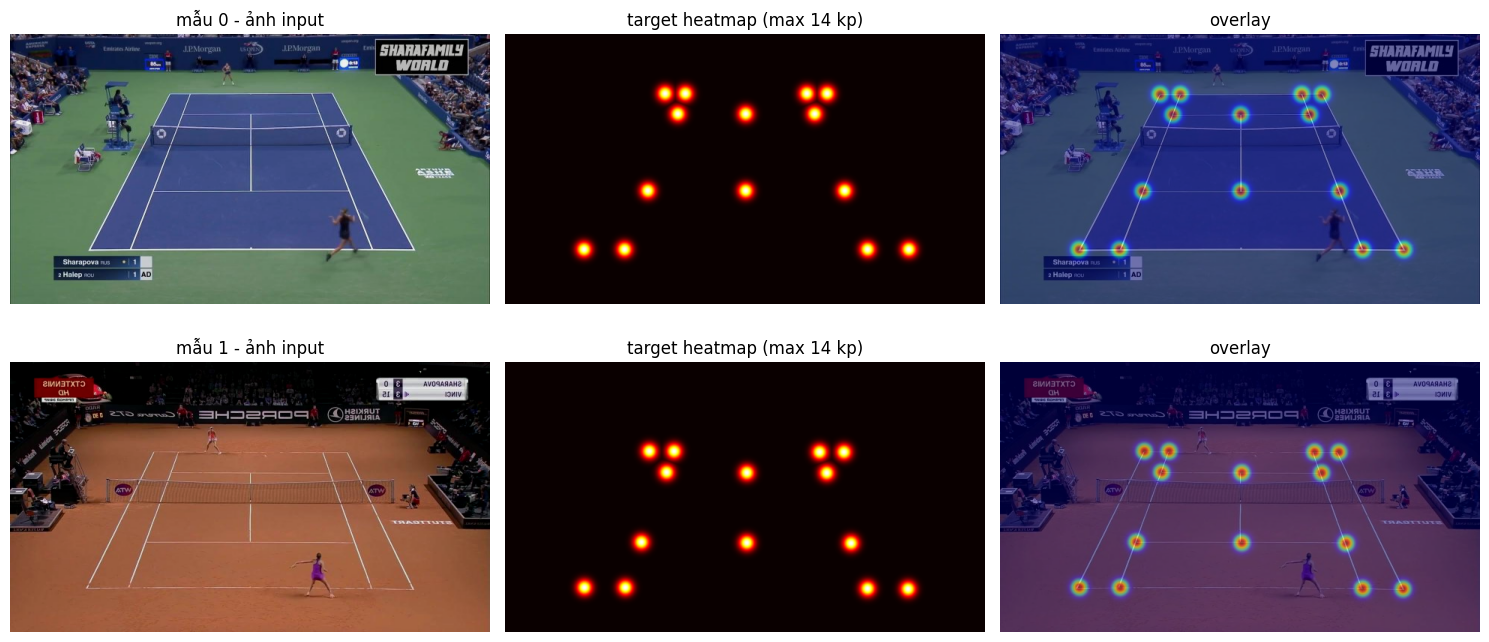

In [35]:
import matplotlib.pyplot as plt

for bi, bt, bv in ds_tr.take(1):
    break
bi, bt, bv = bi.numpy(), bt.numpy(), bv.numpy()
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i in range(2):
    hm = bt[i, :, :, :N_KPS].max(axis=-1)
    axes[i, 0].imshow(bi[i]); axes[i, 0].set_title(f"mẫu {i} - ảnh input")
    axes[i, 1].imshow(hm, cmap="hot"); axes[i, 1].set_title("target heatmap (max 14 kp)")
    axes[i, 2].imshow(bi[i]); axes[i, 2].imshow(hm, cmap="jet", alpha=0.45)
    axes[i, 2].set_title("overlay")
    for ax in axes[i]: ax.axis("off")
plt.tight_layout(); plt.show()


## 4. Finetune (2 phase, custom training loop)

- **Loss:** MSE trên output sigmoid vs Gaussian target; keypoint invisible bị mask khỏi loss.
- **Phase 1:** freeze encoder (block `conv1`–`conv10`), chỉ train decoder với LR cao.
- **Phase 2:** unfreeze toàn mạng, LR nhỏ. Lưu checkpoint tốt nhất theo val loss.

In [37]:
import time

def masked_mse(tgt, pred, vis):
    # tgt, pred: BxHxWx15 ; vis: Bx14
    kp_t, kp_p = tgt[..., :N_KPS], pred[..., :N_KPS]
    v = tf.reshape(tf.cast(vis, tf.float32), (-1, 1, 1, N_KPS))
    kp_loss = tf.reduce_sum(tf.square(kp_p - kp_t) * v) / (tf.reduce_sum(v) * IMG_H * IMG_W + 1e-6)
    bg_loss = tf.reduce_mean(tf.square(pred[..., N_KPS] - tgt[..., N_KPS]))
    return kp_loss + 0.5 * bg_loss

@tf.function
def train_step(model, opt, img, tgt, vis):
    with tf.GradientTape() as tape:
        pred = model(img, training=True)
        loss = masked_mse(tgt, pred, vis)
    grads = tape.gradient(loss, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    return loss

@tf.function
def val_step(model, img, tgt, vis):
    return masked_mse(tgt, model(img, training=False), vis)

def set_encoder_frozen(model, frozen):
    enc = {f"conv{i}_{s}" for i in range(1, 11) for s in ("conv", "relu", "bn")}
    for l in model.layers:
        if l.name in enc:
            l.trainable = not frozen

def run_phase(model, opt, epochs, tag, best_loss):
    hist = {"tr": [], "va": []}
    for ep in range(epochs):
        t0 = time.time()
        tl, n = 0.0, 0
        for img, tgt, vis in ds_tr:
            tl += float(train_step(model, opt, img, tgt, vis)) * img.shape[0]
            n += img.shape[0]
        vl, m = 0.0, 0
        for img, tgt, vis in ds_va:
            vl += float(val_step(model, img, tgt, vis)) * img.shape[0]
            m += img.shape[0]
        tl, vl = tl / n, vl / m
        hist["tr"].append(tl); hist["va"].append(vl)
        msg = "[" + tag + "] epoch " + str(ep + 1) + "/" + str(epochs)
        print(msg + "  train=%.4f  val=%.4f  (%ds)" % (tl, vl, time.time() - t0))
        if vl < best_loss:
            best_loss = vl
            model.save_weights(f"{OUT_DIR}/best_{tag}.weights.h5")
            print("  -> luu best_" + tag + ".weights.h5 (val=%.4f)" % vl)
    return hist, best_loss

model = build_court_heatmap_net()
transfer_pt_to_keras(WEIGHTS_PT, model)

best_loss = float("inf")
hist_all = {}

set_encoder_frozen(model, True)
ntr = sum(int(np.prod(v.shape)) for v in model.trainable_variables)
print("phase1 trainable params: %.1fM" % (ntr / 1e6))
opt = tf.keras.optimizers.Adam(LR_HEAD)
h, best_loss = run_phase(model, opt, EPOCHS_FREEZE, "freeze", best_loss)
hist_all["freeze"] = h

set_encoder_frozen(model, False)
opt = tf.keras.optimizers.Adam(LR_FULL)
opt.build(model.trainable_variables) 
h, best_loss = run_phase(model, opt, EPOCHS_FULL, "full", best_loss)
hist_all["full"] = h
print("best val loss:", best_loss)


chuyen weights .pt -> Keras xong: /content/court_data/court_data/model_tennis_court_det.pt
phase1 trainable params: 2.9M
[freeze] epoch 1/5  train=0.4227  val=0.3693  (715s)
  -> luu best_freeze.weights.h5 (val=0.3693)
[freeze] epoch 2/5  train=0.2714  val=0.1688  (763s)
  -> luu best_freeze.weights.h5 (val=0.1688)
[freeze] epoch 3/5  train=0.1027  val=0.0575  (735s)
  -> luu best_freeze.weights.h5 (val=0.0575)
[freeze] epoch 4/5  train=0.0378  val=0.0244  (744s)
  -> luu best_freeze.weights.h5 (val=0.0244)
[freeze] epoch 5/5  train=0.0180  val=0.0133  (726s)
  -> luu best_freeze.weights.h5 (val=0.0133)
[full] epoch 1/15  train=0.0124  val=0.0116  (736s)
  -> luu best_full.weights.h5 (val=0.0116)
[full] epoch 2/15  train=0.0110  val=0.0104  (727s)
  -> luu best_full.weights.h5 (val=0.0104)
[full] epoch 3/15  train=0.0099  val=0.0094  (723s)
  -> luu best_full.weights.h5 (val=0.0094)
[full] epoch 4/15  train=0.0090  val=0.0086  (711s)
  -> luu best_full.weights.h5 (val=0.0086)
[full] ep

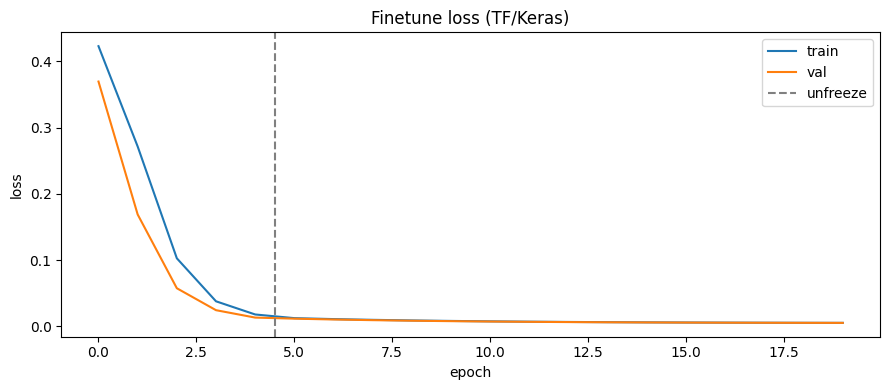

In [38]:
import matplotlib.pyplot as plt
tr = hist_all["freeze"]["tr"] + hist_all["full"]["tr"]
va = hist_all["freeze"]["va"] + hist_all["full"]["va"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tr, label="train"); ax.plot(va, label="val")
ax.axvline(EPOCHS_FREEZE - 0.5, color="gray", ls="--", label="unfreeze")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend(); ax.set_title("Finetune loss (TF/Keras)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/loss_curve.png", dpi=120); plt.show()


## 5. Đánh giá: mean pixel error & PCK

Argmax trên từng heatmap keypoint → so khoảng cách pixel với ground truth (chỉ keypoint visible). PCK@10/20 = tỉ lệ keypoint lỗi dưới 10/20 pixel (hệ 640×360).

In [39]:
import numpy as np

def evaluate(keras_model, records):
    errs = []
    for r in records:
        img, _, vis = load_sample(r, augment=False)
        pred = keras_model.predict(img[None], verbose=0)[0]  # HxWx15
        kps = (np.array(r["kps"], dtype=np.float32).reshape(N_KPS, 2)
               * np.array([IMG_W, IMG_H]))
        for k in range(N_KPS):
            if vis[k]:
                py, px = np.unravel_index(pred[:, :, k].argmax(), (IMG_H, IMG_W))
                errs.append(math.hypot(px - kps[k, 0], py - kps[k, 1]))
    errs = np.array(errs)
    return dict(mean=float(errs.mean()), median=float(np.median(errs)),
                pck10=float((errs < 10).mean()), pck20=float((errs < 20).mean()),
                n=int(len(errs)))

print("--- TRUOC finetune ---")
before = evaluate(model_before, va_recs)
print({k: round(v, 2) for k, v in before.items()})
print("--- SAU finetune (best checkpoint) ---")
model.load_weights(f"{OUT_DIR}/best_full.weights.h5")
after = evaluate(model, va_recs)
print({k: round(v, 2) for k, v in after.items()})
imp = 100 * (before["mean"] - after["mean"]) / before["mean"]
print("cai thien mean error: %.2f -> %.2f px (%.1f%%)" % (before["mean"], after["mean"], imp))


--- TRUOC finetune ---
{'mean': 22.92, 'median': 22.55, 'pck10': 0.02, 'pck20': 0.17, 'n': 14294}
--- SAU finetune (best checkpoint) ---
{'mean': 288.84, 'median': 320.68, 'pck10': 0.28, 'pck20': 0.28, 'n': 14294}
cai thien mean error: 22.92 -> 288.84 px (-1160.2%)


## 6. Visualize

Mỗi hàng là 1 ảnh val: **xanh lá** = ground truth, **đỏ** = model gốc, **cyan** = model sau finetune. Kèm heatmap (max 14 keypoint) trước/sau.

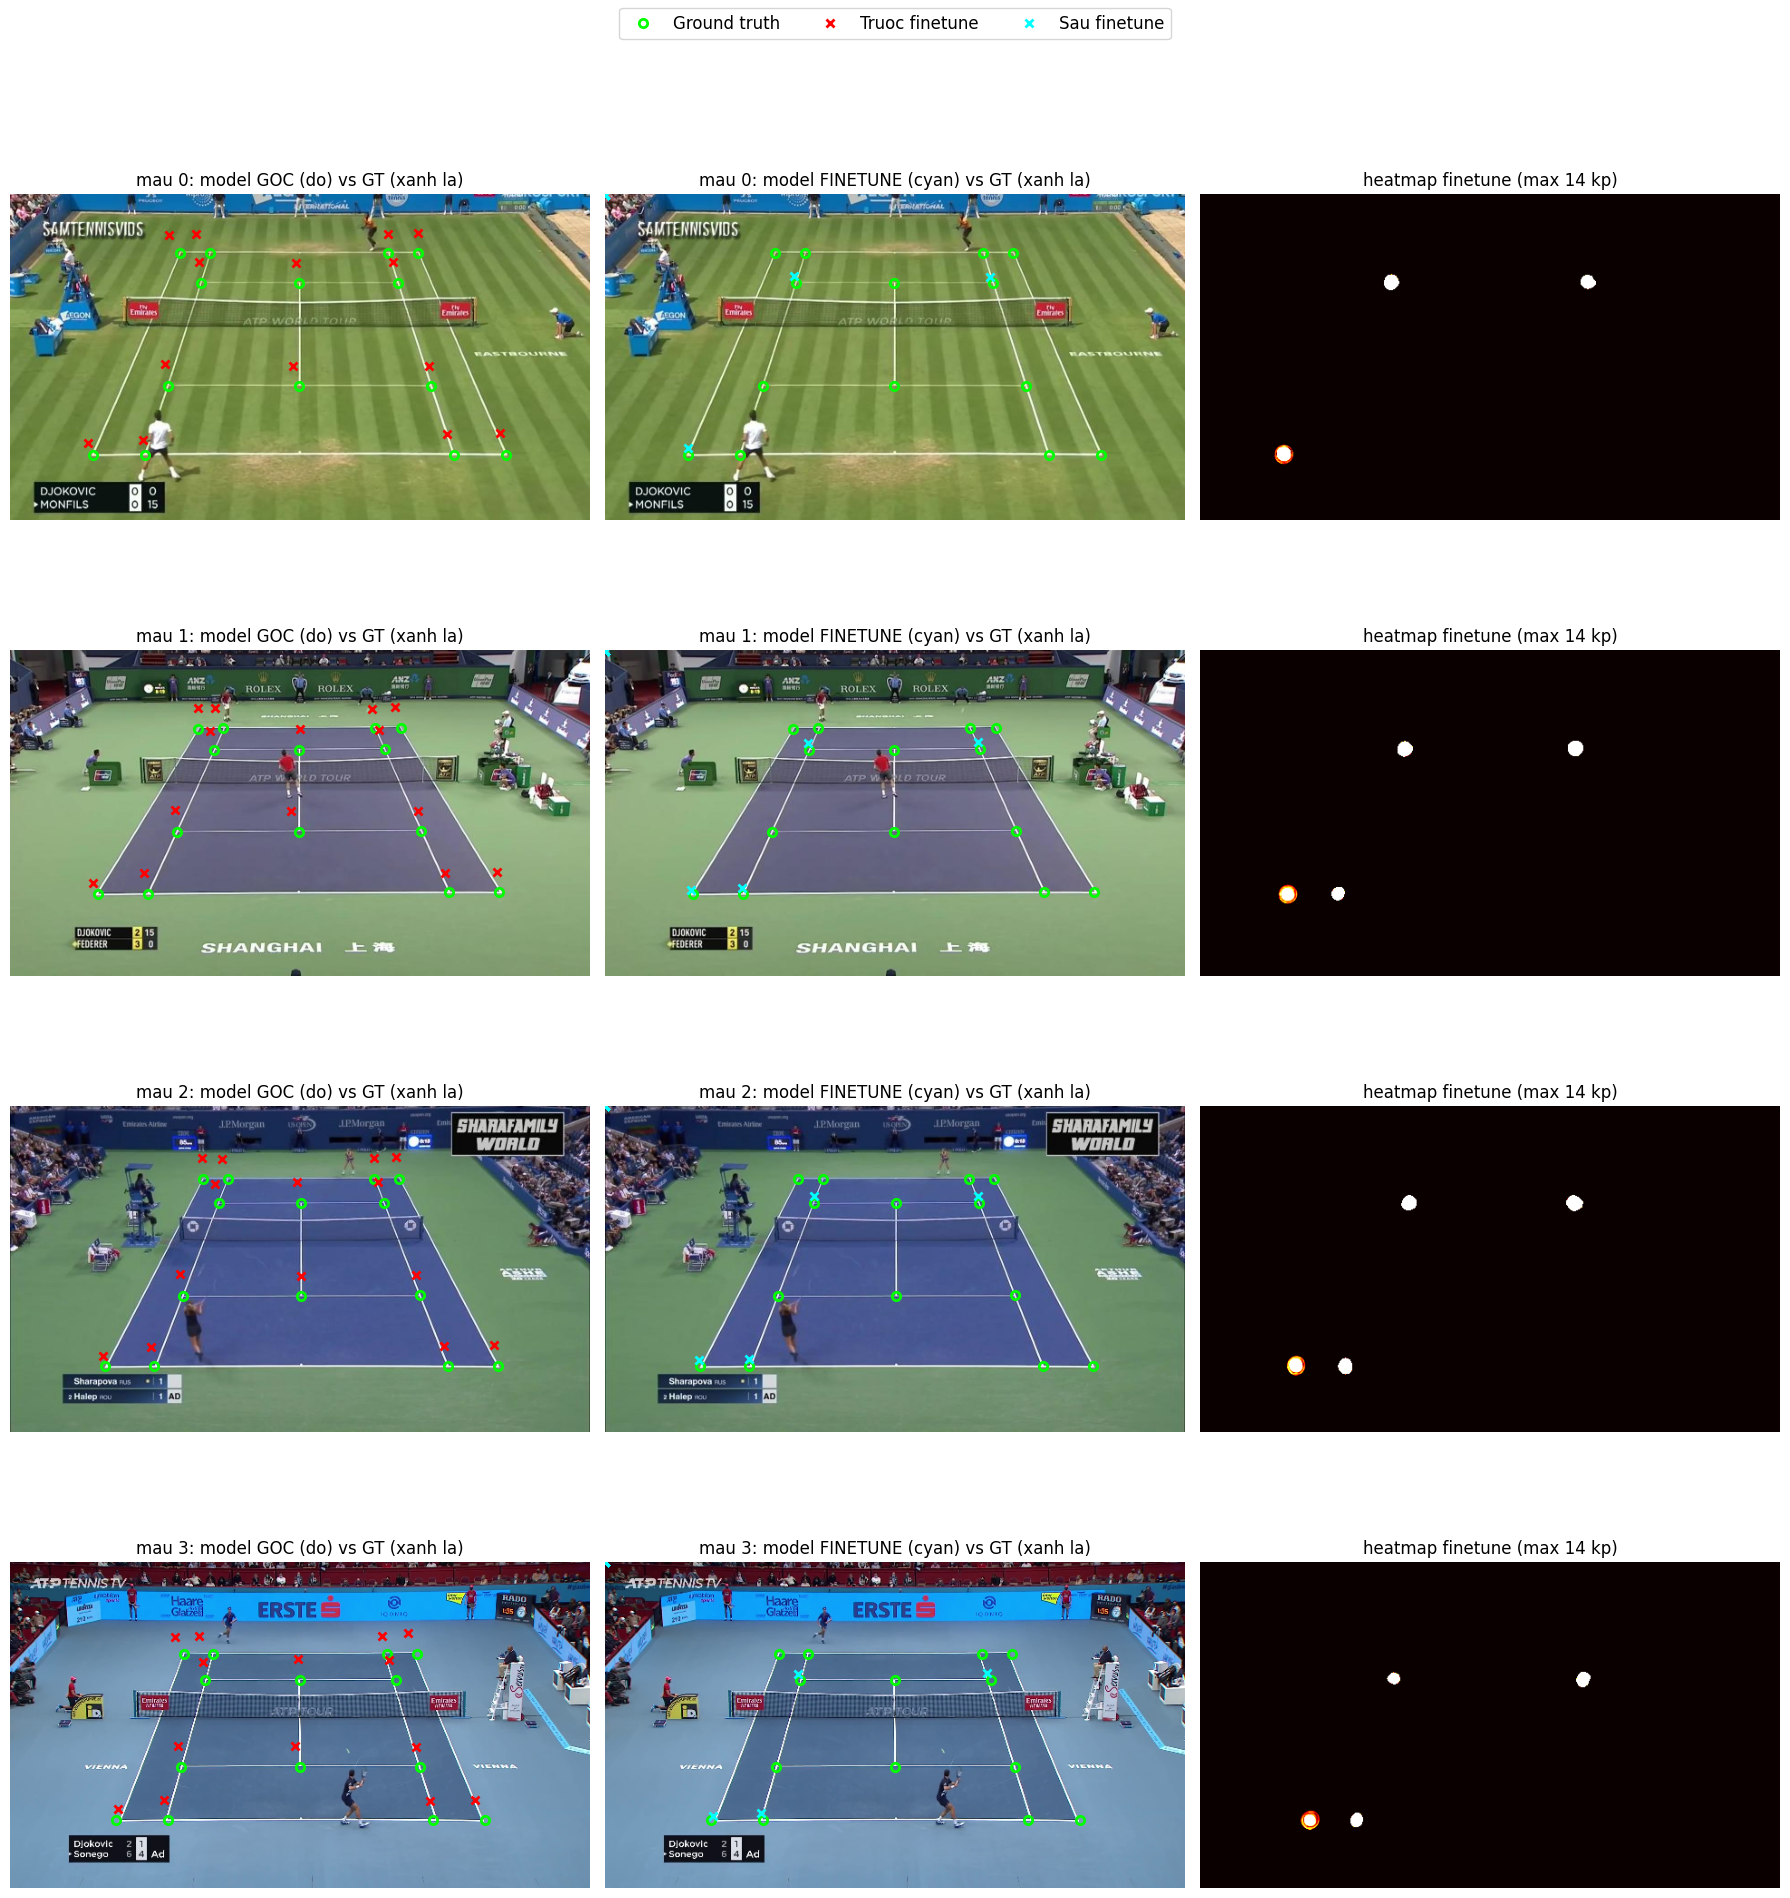

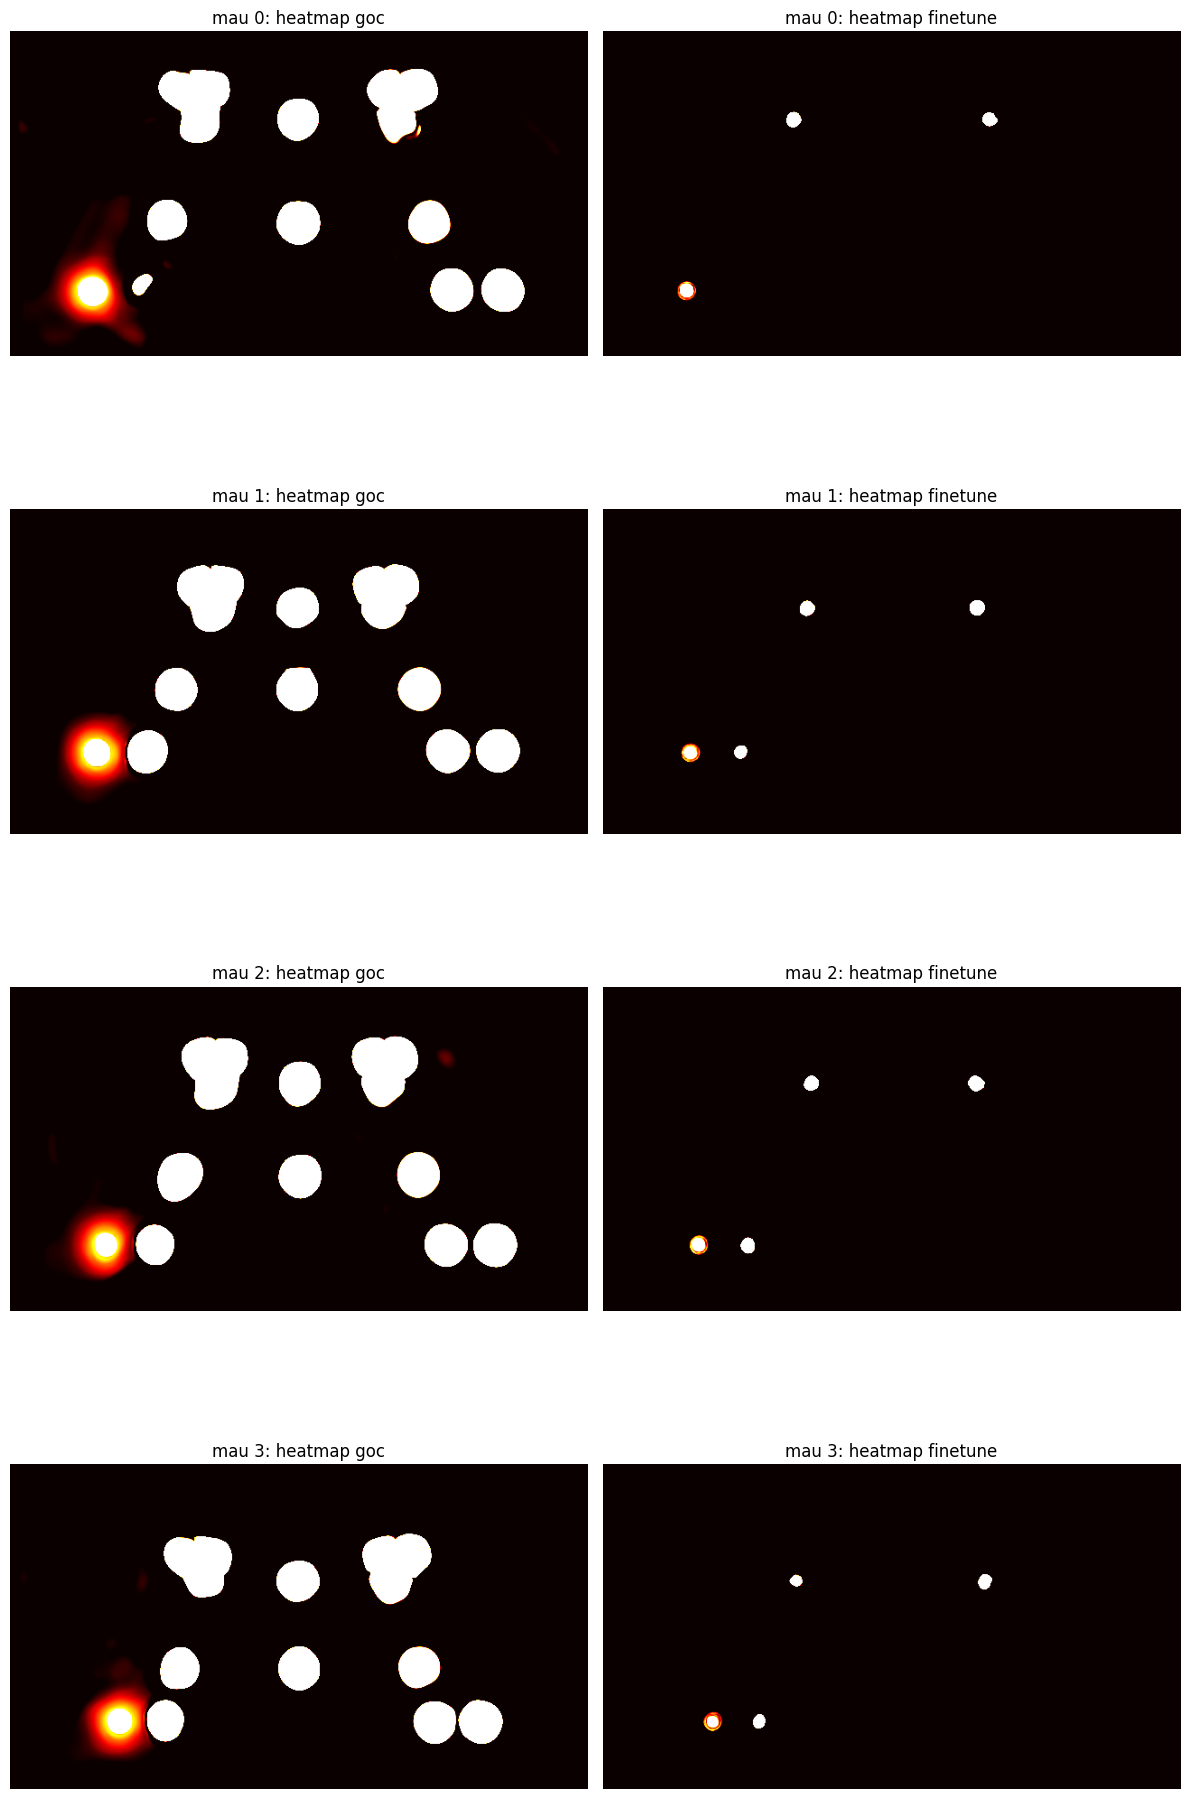

da luu anh vao /content/drive/MyDrive/tennis/court/finetune_tf_out


In [40]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def predict_kps_np(m, img):
    hm = m.predict(img[None], verbose=0)[0][:, :, :N_KPS]  # HxWx14
    pts = []
    for k in range(N_KPS):
        py, px = np.unravel_index(hm[:, :, k].argmax(), (IMG_H, IMG_W))
        pts.append((px, py, float(hm[:, :, k].max())))
    return np.array(pts), hm

def visualize_compare(m_before, m_after, records, n=4):
    fig, axes = plt.subplots(n, 3, figsize=(18, 5 * n))
    if n == 1:
        axes = axes.reshape(1, -1)
    for i in range(n):
        img, _, vis = load_sample(records[i], augment=False)
        gt = (np.array(records[i]["kps"], dtype=np.float32).reshape(N_KPS, 2)
              * np.array([IMG_W, IMG_H]))
        pb, hmb = predict_kps_np(m_before, img)
        pa, hma = predict_kps_np(m_after, img)
        axes[i, 0].imshow(img); axes[i, 0].set_title(f"mau {i}: model GOC (do) vs GT (xanh la)")
        axes[i, 1].imshow(img); axes[i, 1].set_title(f"mau {i}: model FINETUNE (cyan) vs GT (xanh la)")
        axes[i, 2].imshow(hma.max(axis=-1), cmap="hot"); axes[i, 2].set_title("heatmap finetune (max 14 kp)")
        for j in range(N_KPS):
            if vis[j]:
                axes[i, 0].plot(gt[j, 0], gt[j, 1], "o", ms=6, mec="lime", mfc="none", mew=2)
                axes[i, 1].plot(gt[j, 0], gt[j, 1], "o", ms=6, mec="lime", mfc="none", mew=2)
                axes[i, 0].plot(pb[j, 0], pb[j, 1], "x", ms=6, mec="red", mew=2)
                axes[i, 1].plot(pa[j, 0], pa[j, 1], "x", ms=6, mec="cyan", mew=2)
        for ax in axes[i]:
            ax.axis("off")
    legend = [Line2D([0], [0], marker="o", color="w", mec="lime", mfc="none", mew=2, label="Ground truth"),
              Line2D([0], [0], marker="x", color="w", mec="red", mew=2, label="Truoc finetune"),
              Line2D([0], [0], marker="x", color="w", mec="cyan", mew=2, label="Sau finetune")]
    fig.legend(handles=legend, loc="upper center", ncol=3, fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(f"{OUT_DIR}/compare_before_after.png", dpi=120)
    plt.show()

    fig2, ax2 = plt.subplots(n, 2, figsize=(12, 5 * n))
    if n == 1:
        ax2 = ax2.reshape(1, -1)
    for i in range(n):
        img, _, _ = load_sample(records[i], augment=False)
        _, hmb = predict_kps_np(m_before, img)
        _, hma = predict_kps_np(m_after, img)
        ax2[i, 0].imshow(hmb.max(axis=-1), cmap="hot"); ax2[i, 0].set_title(f"mau {i}: heatmap goc")
        ax2[i, 1].imshow(hma.max(axis=-1), cmap="hot"); ax2[i, 1].set_title(f"mau {i}: heatmap finetune")
        ax2[i, 0].axis("off"); ax2[i, 1].axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/heatmap_before_after.png", dpi=120); plt.show()

visualize_compare(model_before, model, va_recs, n=4)
print("da luu anh vao", OUT_DIR)


## 6b. Visualize

Nhìn sâu vào bên trong `CourtHeatmapNet` sau finetune:
1. **14 heatmap riêng lẻ** — mỗi keypoint một heatmap kèm confidence
2. **Feature map từng stage** — model "nhìn" gì ở mỗi độ phân giải (encoder → bottleneck → decoder)
3. **Filter lớp conv1** — 64 filter 3×3 đầu tiên học được gì
4. **Sơ đồ kiến trúc** đầy đủ

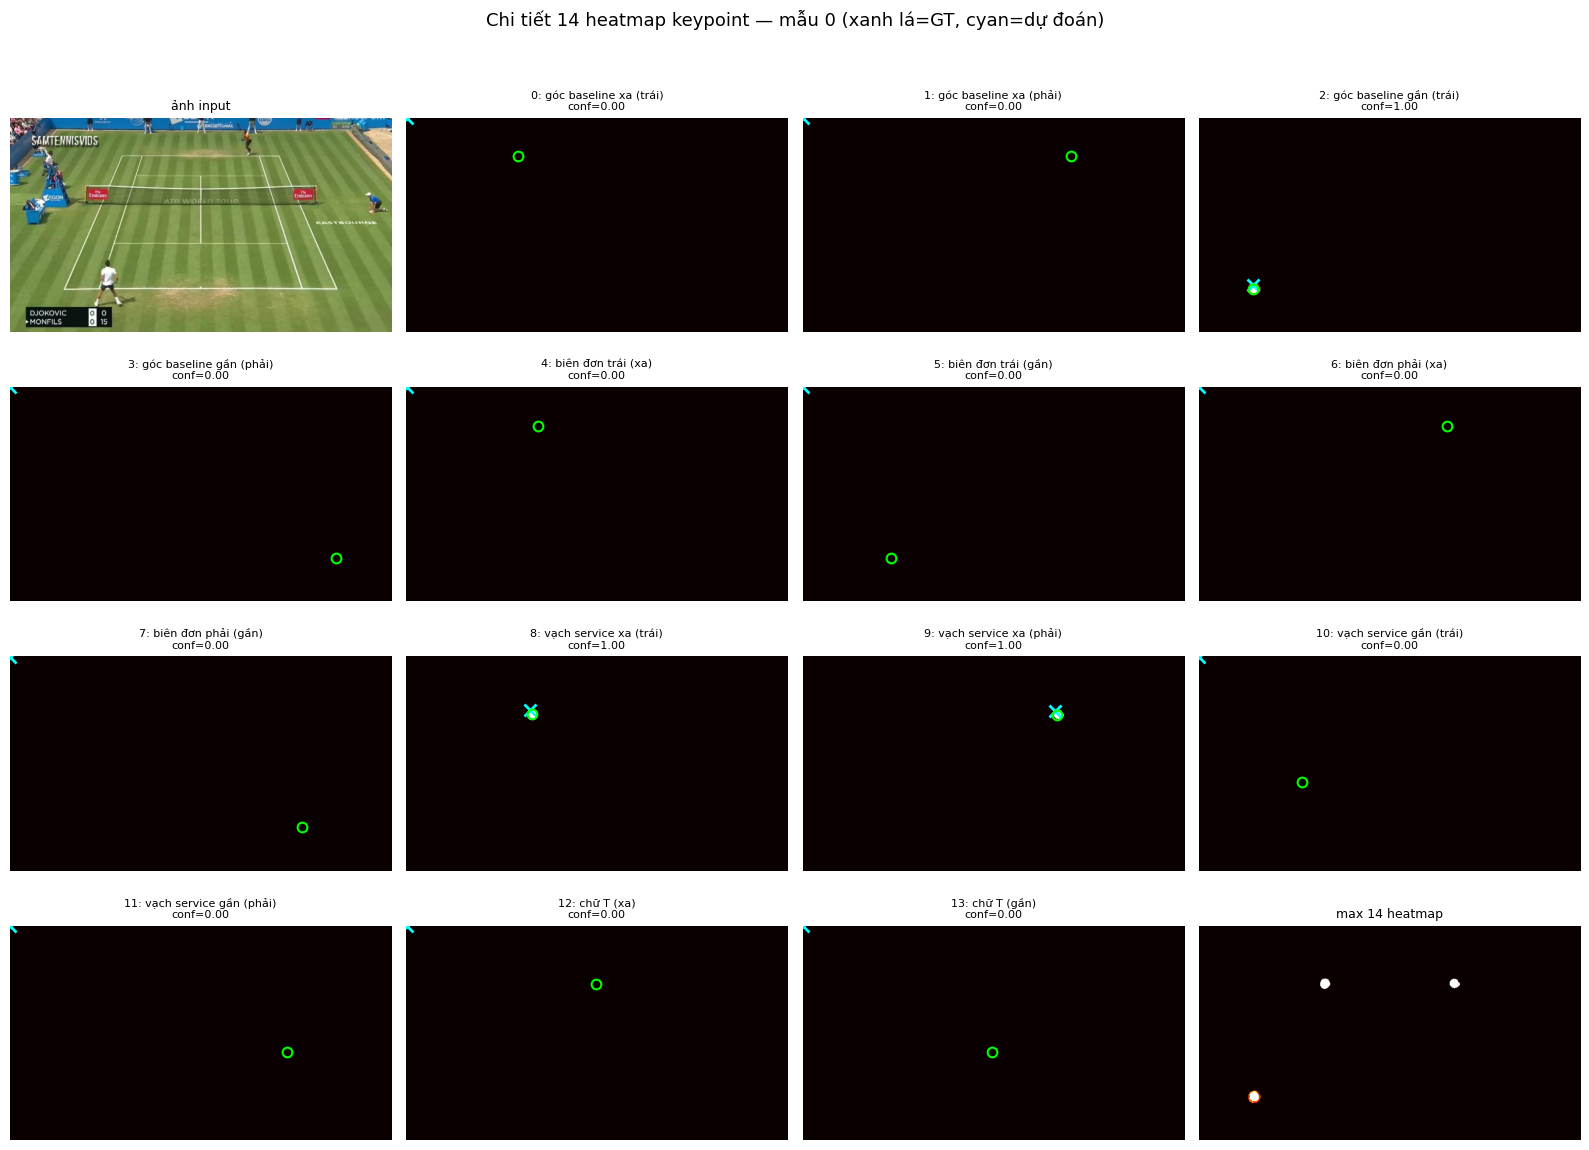

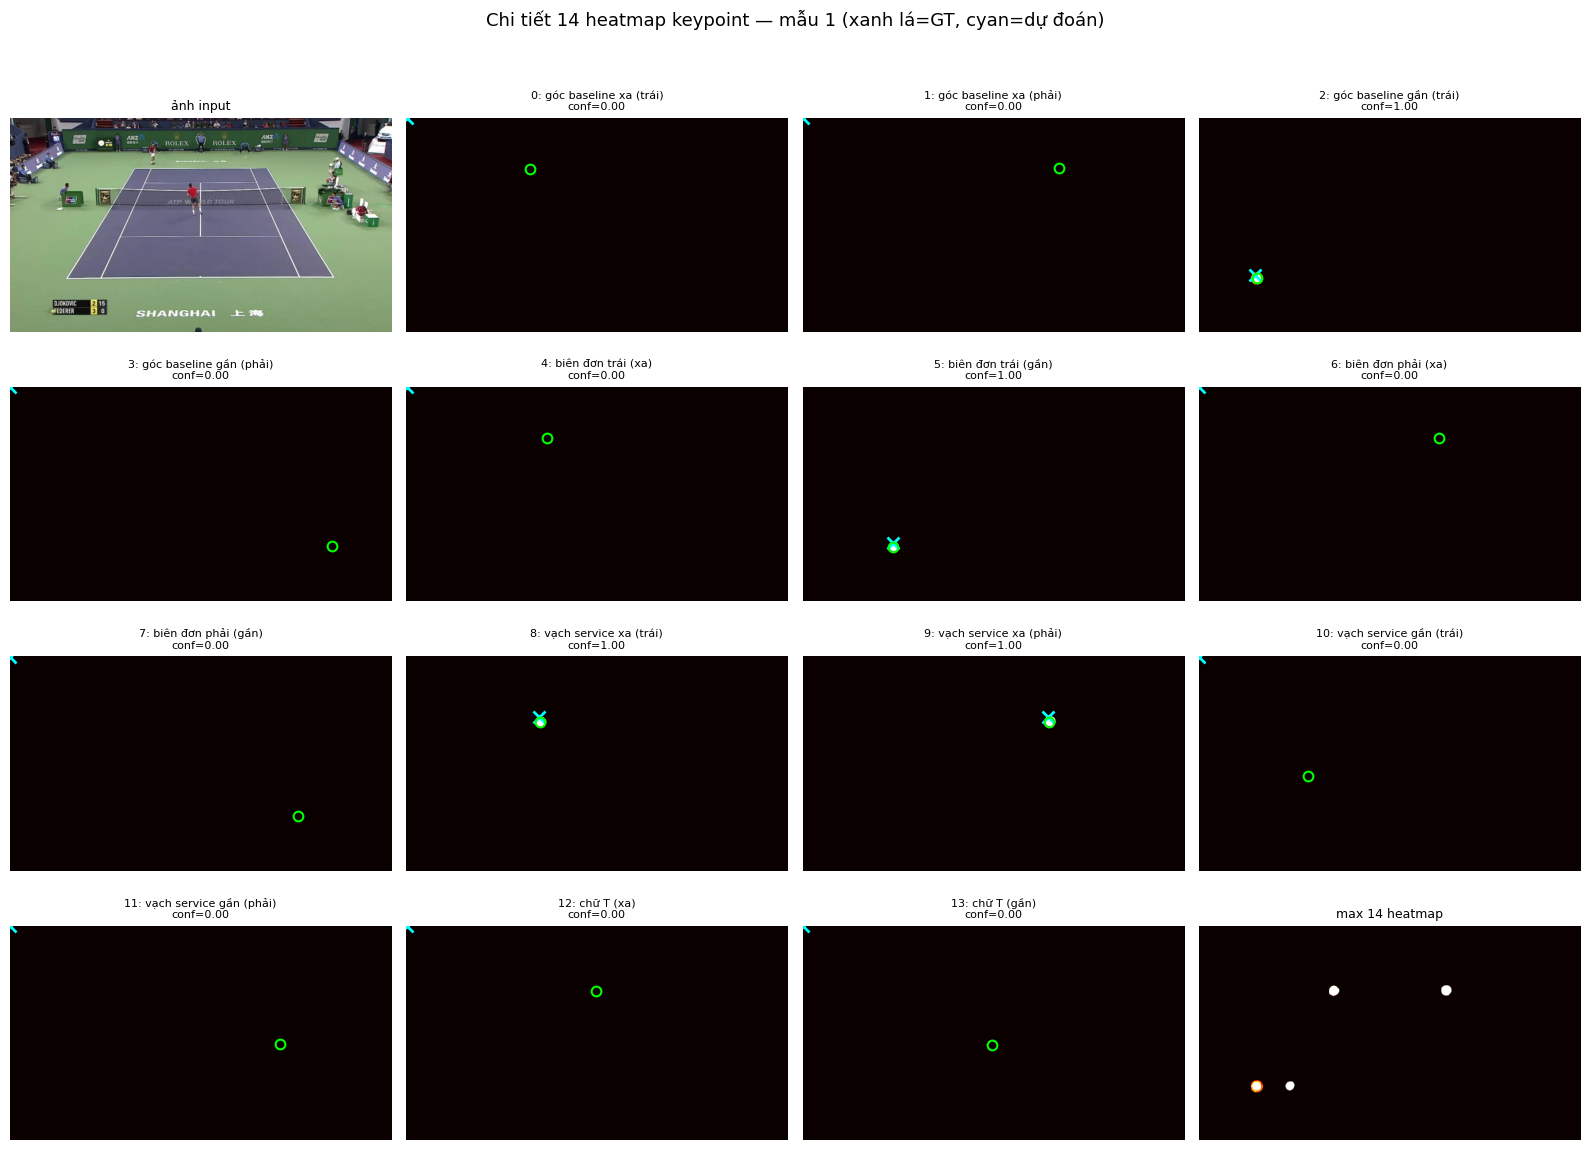

In [41]:
import matplotlib.pyplot as plt
import numpy as np

KP_NAMES = [
    "0: góc baseline xa (trái)", "1: góc baseline xa (phải)",
    "2: góc baseline gần (trái)", "3: góc baseline gần (phải)",
    "4: biên đơn trái (xa)", "5: biên đơn trái (gần)",
    "6: biên đơn phải (xa)", "7: biên đơn phải (gần)",
    "8: vạch service xa (trái)", "9: vạch service xa (phải)",
    "10: vạch service gần (trái)", "11: vạch service gần (phải)",
    "12: chữ T (xa)", "13: chữ T (gần)",
]

def visualize_heatmaps_detail(m, records, n=2):
    for s in range(n):
        img, _, vis = load_sample(records[s], augment=False)
        gt = (np.array(records[s]["kps"], dtype=np.float32).reshape(N_KPS, 2)
              * np.array([IMG_W, IMG_H]))
        hm = m.predict(img[None], verbose=0)[0][:, :, :N_KPS]  # HxWx14
        fig, axes = plt.subplots(4, 4, figsize=(16, 12))
        axes = axes.ravel()
        axes[0].imshow(img); axes[0].set_title("ảnh input", fontsize=9); axes[0].axis("off")
        for k in range(N_KPS):
            ax = axes[k + 1]
            h = hm[:, :, k]
            ax.imshow(h, cmap="hot", vmin=0, vmax=1)
            py, px = np.unravel_index(h.argmax(), h.shape)
            ax.plot(px, py, "x", ms=8, mec="cyan", mew=2)          # dự đoán
            if vis[k]:
                ax.plot(gt[k, 0], gt[k, 1], "o", ms=7,              # ground truth
                        mec="lime", mfc="none", mew=1.5)
            ax.set_title(KP_NAMES[k] + "\nconf=%.2f" % h.max(), fontsize=8)
            ax.axis("off")
        axes[15].imshow(hm.max(axis=-1), cmap="hot", vmin=0, vmax=1)
        axes[15].set_title("max 14 heatmap", fontsize=9); axes[15].axis("off")
        fig.suptitle("Chi tiết 14 heatmap keypoint — mẫu %d (xanh lá=GT, cyan=dự đoán)" % s, fontsize=13)
        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.savefig("%s/heatmap_detail_%d.png" % (OUT_DIR, s), dpi=110)
        plt.show()

visualize_heatmaps_detail(model, va_recs, n=2)


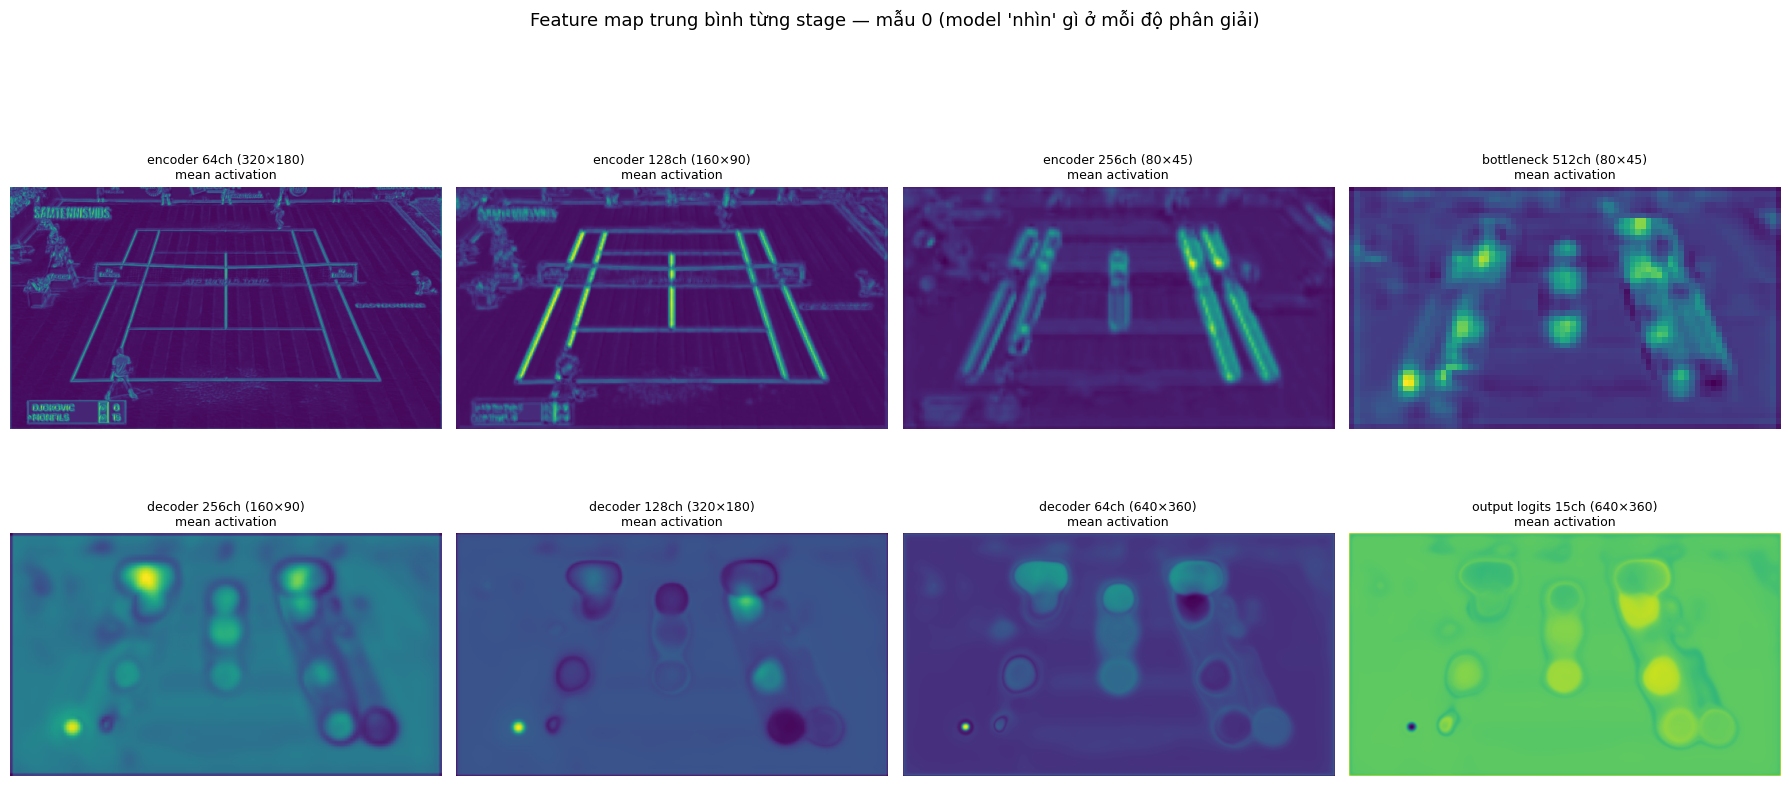

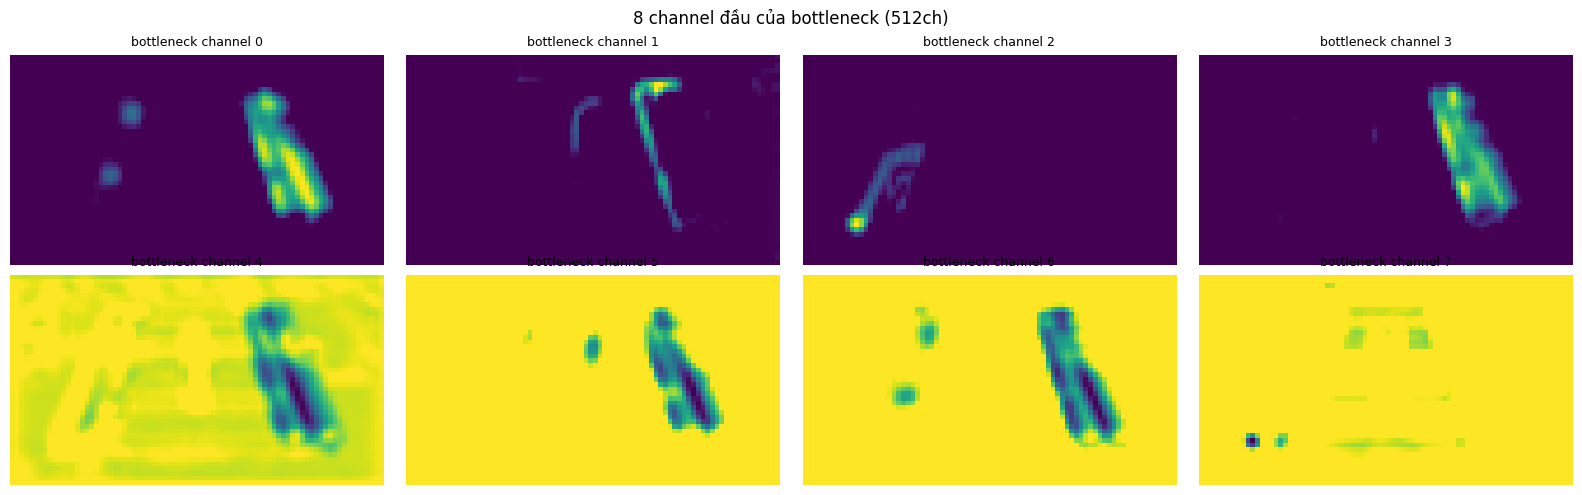

In [42]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_feature_maps(m, records, s=0):
    img, _, _ = load_sample(records[s], augment=False)
    stages = [
        ("conv2_bn",  "encoder 64ch (320×180)"),
        ("conv4_bn",  "encoder 128ch (160×90)"),
        ("conv7_bn",  "encoder 256ch (80×45)"),
        ("conv10_bn", "bottleneck 512ch (80×45)"),
        ("conv13_bn", "decoder 256ch (160×90)"),
        ("conv15_bn", "decoder 128ch (320×180)"),
        ("conv17_bn", "decoder 64ch (640×360)"),
        ("conv18_conv", "output logits 15ch (640×360)"),
    ]
    sub = tf.keras.Model(m.input, [m.get_layer(n).output for n, _ in stages])
    feats = sub.predict(img[None], verbose=0)
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    for ax, f, (lname, title) in zip(axes.ravel(), feats, stages):
        ax.imshow(f[0].mean(axis=-1), cmap="viridis")
        ax.set_title(title + "\nmean activation", fontsize=9)
        ax.axis("off")
    fig.suptitle("Feature map trung bình từng stage — mẫu %d (model 'nhìn' gì ở mỗi độ phân giải)" % s, fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig("%s/feature_maps_%d.png" % (OUT_DIR, s), dpi=110)
    plt.show()

    # 8 channel đầu của bottleneck: mỗi channel "chú ý" một vùng khác nhau
    bneck = feats[3][0]  # 45x80x512
    fig2, ax2 = plt.subplots(2, 4, figsize=(16, 5))
    for j, ax in enumerate(ax2.ravel()):
        ax.imshow(bneck[:, :, j], cmap="viridis")
        ax.set_title("bottleneck channel %d" % j, fontsize=9); ax.axis("off")
    fig2.suptitle("8 channel đầu của bottleneck (512ch)", fontsize=12)
    plt.tight_layout(); plt.savefig("%s/bottleneck_ch_%d.png" % (OUT_DIR, s), dpi=110); plt.show()

visualize_feature_maps(model, va_recs, s=0)


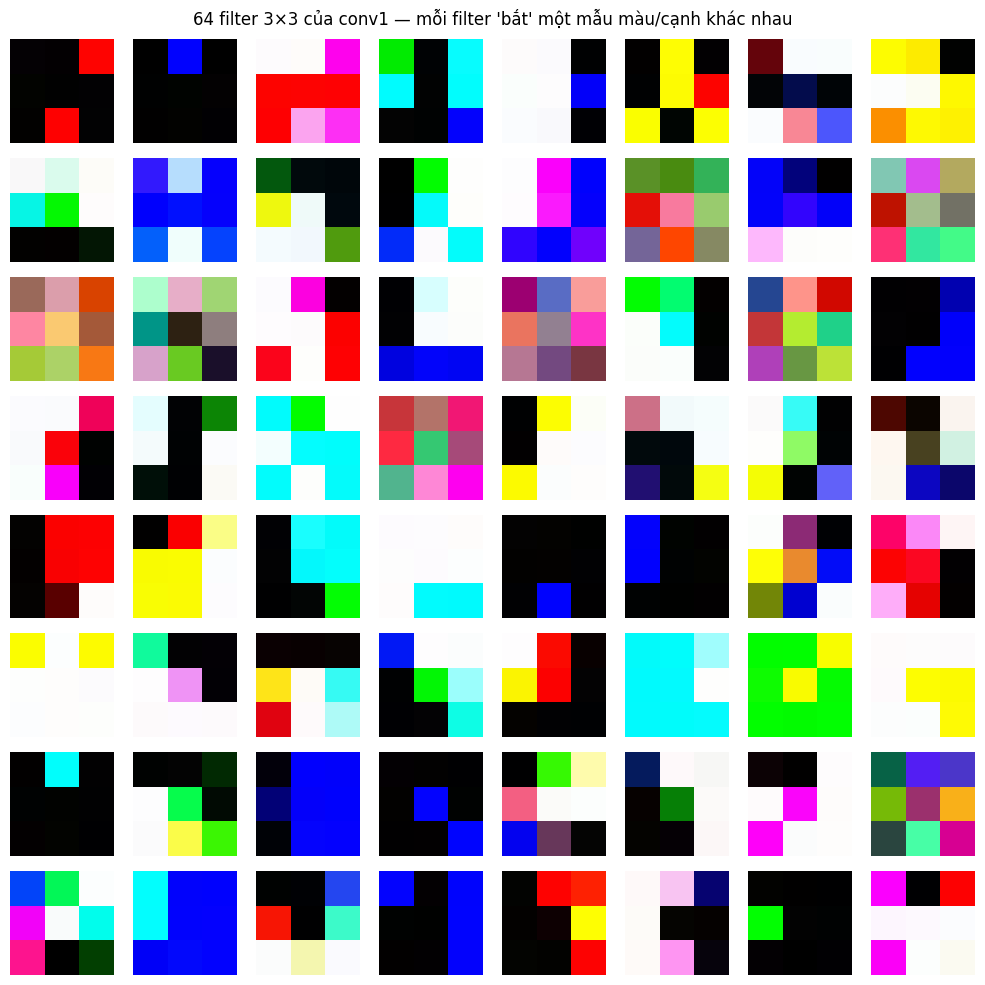

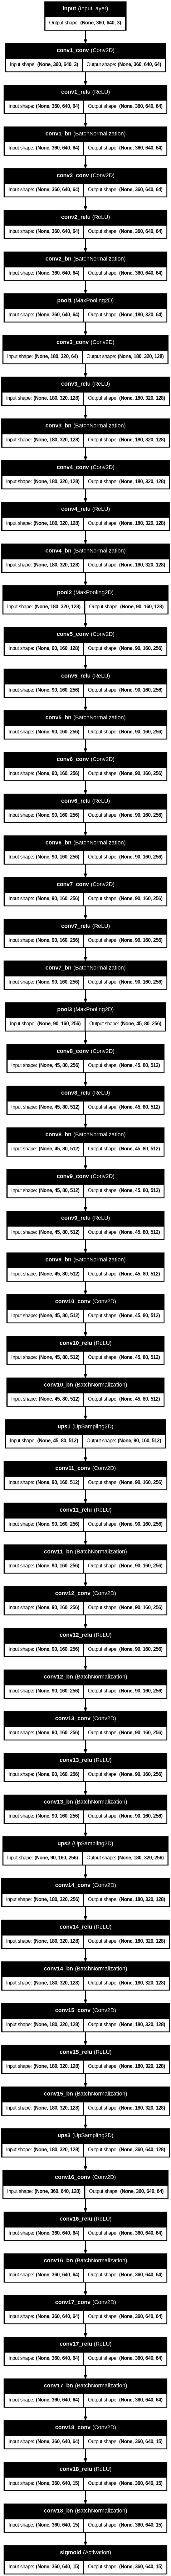

In [43]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_first_filters(m):
    K, b = m.get_layer("conv1_conv").get_weights()  # (3,3,3,64)
    fig, axes = plt.subplots(8, 8, figsize=(10, 10))
    for j, ax in enumerate(axes.ravel()):
        f = K[:, :, :, j]
        f = (f - f.min()) / (f.max() - f.min() + 1e-6)
        ax.imshow(f)
        ax.axis("off")
    fig.suptitle("64 filter 3×3 của conv1 — mỗi filter 'bắt' một mẫu màu/cạnh khác nhau", fontsize=12)
    plt.tight_layout(); plt.savefig("%s/conv1_filters.png" % OUT_DIR, dpi=120); plt.show()

visualize_first_filters(model)

# Sơ đồ kiến trúc đầy đủ (cần pydot + graphviz; tự bỏ qua nếu thiếu)
try:
    tf.keras.utils.plot_model(model, to_file="%s/arch.png" % OUT_DIR,
                              show_shapes=True, show_layer_names=True, dpi=80)
    from IPython.display import Image, display
    display(Image("%s/arch.png" % OUT_DIR))
except Exception as e:
    print("Không vẽ được sơ đồ (thiếu pydot/graphviz):", e)
    print("Cài bằng: pip install pydot  và  apt install graphviz")


## 7. Lưu model

- `court_heatmap_finetuned.weights.h5`: weights Keras.
- `court_heatmap_finetuned.pt`: state_dict PyTorch chuyển ngược từ Keras (transpose kernel `(3,3,I,O)` → `(O,I,3,3)`, map BatchNorm + `num_batches_tracked`) — **thay trực tiếp vào `models/` của dự án là chạy được**, vì runtime load bằng `load_state_dict` vào `CourtHeatmapNet`.

In [44]:
# 7a. lưu weights Keras
model.save_weights(f"{OUT_DIR}/court_heatmap_finetuned.weights.h5")
print("da luu:", f"{OUT_DIR}/court_heatmap_finetuned.weights.h5")

# 7b. chuyển ngược Keras -> PyTorch .pt (để dùng trong pipeline gốc)
def transfer_keras_to_pt(keras_model):
    import torch
    sd = {}
    for i in range(1, 19):
        name = f"conv{i}"
        K, b = keras_model.get_layer(f"{name}_conv").get_weights()   # (3,3,I,O), (O,)
        gamma, beta, mean, var = keras_model.get_layer(f"{name}_bn").get_weights()
        sd[f"{name}.block.0.weight"] = torch.from_numpy(K.transpose(3, 2, 0, 1).copy())
        sd[f"{name}.block.0.bias"] = torch.from_numpy(b.copy())
        sd[f"{name}.block.2.weight"] = torch.from_numpy(gamma.copy())
        sd[f"{name}.block.2.bias"] = torch.from_numpy(beta.copy())
        sd[f"{name}.block.2.running_mean"] = torch.from_numpy(mean.copy())
        sd[f"{name}.block.2.running_var"] = torch.from_numpy(var.copy())
        sd[f"{name}.block.2.num_batches_tracked"] = torch.tensor(0, dtype=torch.long)
    return sd

sd = transfer_keras_to_pt(model)
torch.save(sd, f"{OUT_DIR}/court_heatmap_finetuned.pt")
print("da luu:", f"{OUT_DIR}/court_heatmap_finetuned.pt")

# 7c. tóm tắt
import json
summary = {
    "framework": "tensorflow/keras",
    "weights_goc": WEIGHTS_PT,
    "train_samples": len(tr_recs), "val_samples": len(va_recs),
    "best_val_loss": float(best_loss),
    "eval_before": before, "eval_after": after,
}
json.dump(summary, open(f"{OUT_DIR}/finetune_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))


da luu: /content/drive/MyDrive/tennis/court/finetune_tf_out/court_heatmap_finetuned.weights.h5
da luu: /content/drive/MyDrive/tennis/court/finetune_tf_out/court_heatmap_finetuned.pt
{
  "framework": "tensorflow/keras",
  "weights_goc": "/content/court_data/court_data/model_tennis_court_det.pt",
  "train_samples": 9194,
  "val_samples": 1021,
  "best_val_loss": 0.0052634321912999075,
  "eval_before": {
    "mean": 22.919729288917654,
    "median": 22.545293733370066,
    "pck10": 0.024555757660556878,
    "pck20": 0.17091087169441724,
    "n": 14294
  },
  "eval_after": {
    "mean": 288.83554016677266,
    "median": 320.6774240580202,
    "pck10": 0.28284594934937735,
    "pck20": 0.2847348537848048,
    "n": 14294
  }
}
